# Step 2: Did Harbour's 15% campaigns pay for themselves — and how sure can we be?

**Decision.** Should Harbour repeat its 15% discount on cold coffee and desserts?

**What we did.** The question needs something we cannot observe: what Harbour would have sold *without* the campaign. We built four ways to predict that, from a simple weekday average to a gradient-boosting model. We scored each on ordinary periods it was not trained on and used the best one to estimate each campaign separately. Every result is then translated into gross profit and checked against a break-even level, including under other cost assumptions.

**Short answer.**
- **Measured:** the campaigns gave $472 of discounts.
- **Estimated:** the best predictor puts the extra promoted-item sales at **−5 units in March and −16 in May**, with chance ranges reaching at most +34 (March) and +24 (May). Breaking even needed **+72 (March) and +93 (May)**.
- **Both campaigns, separately,** fall well short. The shortfall holds under every cost assumption we tried.

Gradient boosting did **not** predict better than a plain linear regression, so we do not rely on it. With only two campaigns, the honest conclusion is that there is **no evidence the campaign paid for itself and good evidence that it did not reach break-even at recorded costs.** Harbour should not repeat it unchanged; any repeat should be a randomized test (Section 10).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(ROOT / "data" / "raw" / "stories_transactions.csv")
raw["Date"] = pd.to_datetime(raw["Date"])
print(f"{len(raw):,} lines, {raw['Transaction ID'].nunique():,} purchases, {raw['Date'].min().date()} to {raw['Date'].max().date()}")

51,177 lines, 33,887 purchases, 2026-01-01 to 2026-06-30


## 1. Observed facts: what the campaign was

The data has no campaign label. We define the campaign from the data itself: every line with a 15% discount rate.

In [2]:
P = raw[raw["Discount Rate"] == 0.15]
CAMP_DAYS = pd.DatetimeIndex(sorted(P["Date"].unique()))
ITEMS = sorted(P["Product"].unique())
print("Branches with 15% lines:", P["Branch"].unique().tolist())
print("Campaign days:", [d.strftime("%d %b") for d in CAMP_DAYS])
print("Promoted products:", ITEMS)
on_days = raw[(raw.Branch == "Harbour") & raw.Product.isin(ITEMS) & raw.Date.isin(CAMP_DAYS)]
print("Harbour lines of promoted products on campaign days:", len(on_days), "| rates:", on_days["Discount Rate"].value_counts().to_dict())
discount_given = (P["Quantity"] * P["Unit Price (USD)"] * 0.15).sum()
print(f"Discount given (list price x 15%): ${discount_given:,.2f} on {P['Quantity'].sum()} units")
for m, name in [(3, "March"), (5, "May")]:
    x = P[P.Date.dt.month == m]
    print(f"  {name}: ${(x.Quantity * x['Unit Price (USD)'] * 0.15).sum():,.2f} on {x.Quantity.sum()} units")

Branches with 15% lines: ['Harbour']
Campaign days: ['12 Mar', '13 Mar', '14 Mar', '15 Mar', '16 Mar', '17 Mar', '18 Mar', '19 Mar', '12 May', '13 May', '14 May', '15 May', '16 May', '17 May', '18 May', '19 May']
Promoted products: ['Brownie', 'Cheesecake Slice', 'Coffee Frappe', 'Cold Brew', 'Frozen Yoghurt Cup', 'Iced Americano', 'Iced Latte', 'Iced Mocha', 'Tiramisu Cup']
Harbour lines of promoted products on campaign days: 504 | rates: {0.15: 504}
Discount given (list price x 15%): $472.08 on 542 units
  March: $210.14 on 241 units
  May: $261.94 on 301 units


**Observed:** the 15% rate appears only at Harbour, only on 9 products (5 cold coffees, 4 desserts), and only on 16 days in two blocks of 8 (12–19 March, 12–19 May). On those days *every* Harbour sale of those products was discounted. **Assumption:** this is the campaign as Stories ran it. Its objective and any advertising cost are unknown.

**Note:** $472 of discount is not the same as $472 of lost profit. If the campaign brought in enough extra sales, it could still have paid off. Answering that needs an estimate of what would have sold without it.

## 2. Rejected approach: comparing discounted and full-price baskets

In [3]:
tx = (raw[raw.Branch == "Harbour"].groupby("Transaction ID")
      .agg(rate=("Discount Rate", "max"), items=("Quantity", "sum"), gp=("Line Gross Profit (USD)", "sum")))
display(tx.groupby("rate")[["items", "gp"]].mean().round(2))

,items,gp
rate,,
0.00,1.57,5.97
0.10,1.81,6.20
0.15,1.78,5.72


We rejected this comparison. 15% baskets contain only cold coffee and desserts, so differences reflect **product mix and who chose to buy**, not the discount's effect. It also cannot separate extra sales from discounted sales that would have happened anyway.

## 3. Building the "no-campaign" prediction

**Outcomes** (daily, Harbour): (a) units of the 9 promoted products; (b) total Harbour gross profit. Outcome (b) catches customers switching *from* other products.

**Training data:** ordinary days only, excluding campaign days and the 7 days after each campaign (which the campaign may have affected).

**Inputs:** the inputs leave out any Harbour sales from the same day, which would contain the very effect we want to measure.
- Day of week and a time trend.
- Garden + Uptown sales on the same day, as comparison branches.

**Four candidates**, simplest first:

| Method | Idea |
|---|---|
| Same-weekday average | Mean of the last 4 same weekdays at Harbour |
| Branch ratio (our first version) | Harbour's usual ratio to Garden + Uptown on the same weekday, ±28 days |
| Linear regression | Weekday + trend + comparison-branch sales |
| Gradient boosting (ML) | Same inputs, allows non-linear patterns |

**Assumptions:**
- **A1:** Without the campaign, Harbour's relationship to these inputs would have stayed the same.
- **A2:** The campaign did not change sales at Garden/Uptown. If customers switched branches, the comparison branches were *lowered*, which makes Harbour's estimated lift *too high*. So this assumption can only flatter the campaign.

In [4]:
def build_daily(df):
    df = df.assign(camp=df.Product.isin(ITEMS), H=df.Branch == "Harbour")
    g = (df.groupby(["Date", "H", "camp"])
           .agg(u=("Quantity", "sum"), gp=("Line Gross Profit (USD)", "sum")).unstack(["H", "camp"]))
    g.columns = [f"{a}_{'H' if h else 'C'}_{'camp' if c else 'oth'}" for a, h, c in g.columns]
    g = g.fillna(0)
    g["gp_H"] = g.gp_H_camp + g.gp_H_oth
    g["gp_C"] = g.gp_C_camp + g.gp_C_oth
    g["dow"] = g.index.dayofweek
    g["t"] = (g.index - g.index[0]).days
    for i in range(6):
        g[f"d{i}"] = (g.dow == i).astype(float)
    return g

def masks(index):
    camp = index.isin(CAMP_DAYS)
    post = np.zeros(len(index), bool)
    for end in [CAMP_DAYS[7], CAMP_DAYS[-1]]:
        post |= (index > end) & (index <= end + pd.Timedelta(days=7))
    return camp, post, ~camp & ~post

DOW = [f"d{i}" for i in range(6)]
OUTCOMES = {
    "promoted units": {"y": "u_H_camp", "ctrl": "u_C_camp", "X": ["t", "u_C_camp", "u_C_oth"] + DOW},
    "other-item units": {"y": "u_H_oth", "ctrl": "u_C_oth", "X": ["t", "u_C_camp", "u_C_oth"] + DOW},
    "Harbour gross profit $": {"y": "gp_H", "ctrl": "gp_C", "X": ["t", "gp_C"] + DOW},
}

def predict(g, method, spec, train, test):
    tr, te, y, c = g[train], g[test], spec["y"], spec["ctrl"]
    if method == "Same-weekday average":
        out = []
        for day in te.index:
            h = tr[(tr.index < day) & (tr.dow == day.dayofweek)].tail(4)
            out.append((h if len(h) else tr[tr.dow == day.dayofweek].head(4))[y].mean())
        return np.array(out)
    if method == "Branch ratio":
        out = []
        for day in te.index:
            loc = tr[(np.abs((tr.index - day).days) <= 28) & (tr.dow == day.dayofweek)]
            out.append(te.loc[day, c] * loc[y].sum() / loc[c].sum())
        return np.array(out)
    if method == "Linear regression":
        return LinearRegression().fit(tr[spec["X"]], tr[y]).predict(te[spec["X"]])
    if method == "Gradient boosting":
        m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3, min_samples_leaf=10, random_state=0)
        return m.fit(tr[spec["X"]], tr[y]).predict(te[spec["X"]])

METHODS = ["Same-weekday average", "Branch ratio", "Linear regression", "Gradient boosting"]
daily = build_daily(raw)
CAMP, POST, CLEAN = masks(daily.index)
print("Ordinary (training) days:", CLEAN.sum(), "| campaign days:", CAMP.sum(), "| post-campaign days set aside:", POST.sum())

Ordinary (training) days: 151 | campaign days: 16 | post-campaign days set aside: 14


## 4. Which predictor is best? Testing on 8-day periods the model never saw

For every run of 8 consecutive ordinary days, we hide those days, train each method on the remaining ordinary days and predict the hidden 8. This does two jobs:
1. **Model selection:** which method predicts unseen periods most accurately?
2. **Fake campaign dates:** each hidden period is a "campaign" that never happened. The spread of the prediction errors shows how big an "effect" chance alone produces.

In [5]:
idx = daily.index
clean_set = set(idx[CLEAN])
STARTS = [s for s in idx[CLEAN] if all(s + pd.Timedelta(days=i) in clean_set for i in range(8))]
rows = []
for s in STARTS:
    blk = (idx >= s) & (idx < s + pd.Timedelta(days=8))
    for oname, spec in OUTCOMES.items():
        actual = daily.loc[blk, spec["y"]].values
        for m in METHODS:
            p = predict(daily, m, spec, CLEAN & ~blk, blk)
            rows.append({"outcome": oname, "method": m, "start": s, "err8": actual.sum() - p.sum()})
cv = pd.DataFrame(rows)
score = (cv.groupby(["outcome", "method"])["err8"]
           .agg(mean_abs_8day_error=lambda x: x.abs().mean(), avg_bias="mean",
                chance_5pct=lambda x: x.quantile(0.05), chance_95pct=lambda x: x.quantile(0.95)))
print(len(STARTS), "hidden 8-day periods per method and outcome")
score.round(1)

130 hidden 8-day periods per method and outcome


mean_abs_8day_error  avg_bias  \
outcome                method                                                
Harbour gross profit $ Branch ratio                        268.6      -5.7   
                       Gradient boosting                   224.5      24.8   
                       Linear regression                   174.2     -12.5   
                       Same-weekday average                294.0     221.2   
other-item units       Branch ratio                         50.7      -1.3   
                       Gradient boosting                    41.3      -5.0   
                       Linear regression                    34.2      -3.1   
                       Same-weekday average                 56.0      45.3   
promoted units         Branch ratio                         25.8      -1.2   
                       Gradient boosting                    24.6       0.3   
                       Linear regression                    19.5      -0.5   
                       Same-weekday average                 25.4      14.3   

                                             chance_5pct  chance_95pct  
outcome                method                                           
Harbour gross profit $ Branch ratio               -492.6         519.7  
                       Gradient boosting          -454.9         424.4  
                       Linear regression          -353.3         320.6  
                       Same-weekday average       -226.9         716.6  
other-item units       Branch ratio               -109.9          95.6  
                       Gradient boosting           -77.4          86.4  
                       Linear regression           -65.4          76.9  
                       Same-weekday average        -40.4         140.5  
promoted units         Branch ratio                -45.2          57.0  
                       Gradient boosting           -46.5          53.9  
                       Linear regression           -35.4          39.5  
                       Same-weekday average        -39.6          60.4

In [6]:
best = score["mean_abs_8day_error"].groupby(level=0).idxmin().map(lambda t: t[1])
print("Most accurate method per outcome:", best.to_dict())
lin_vs_gbm = score["mean_abs_8day_error"].unstack()
print("\nGradient boosting error relative to linear regression:")
print((lin_vs_gbm["Gradient boosting"] / lin_vs_gbm["Linear regression"] - 1).map("{:+.0%}".format))

Most accurate method per outcome: {'Harbour gross profit $': 'Linear regression', 'other-item units': 'Linear regression', 'promoted units': 'Linear regression'}

Gradient boosting error relative to linear regression:
outcome
Harbour gross profit $    +29%
other-item units          +21%
promoted units            +26%
dtype: object


**Result.** A **linear regression** predicts held-out periods best for every outcome. Gradient boosting is 21–29% *less* accurate: with about 150 training days and a few simple inputs, it overfits. The same-weekday average is biased (it misses the strong growth from January to June). **We use linear regression as the main estimate and report the other methods as robustness checks.** Here the ML model does not earn its place, and saying so is part of the result.

## 5. Campaign estimates — March and May separately

In [7]:
EPISODES = {"March": CAMP & (idx.month == 3), "May": CAMP & (idx.month == 5)}
est = []
for oname, spec in OUTCOMES.items():
    noise = cv[(cv.outcome == oname) & (cv.method == "Linear regression")]["err8"]
    for ep, mask in EPISODES.items():
        for m in METHODS:
            pred = predict(daily, m, spec, CLEAN, mask).sum()
            act = daily.loc[mask, spec["y"]].sum()
            row = {"outcome": oname, "episode": ep, "method": m, "actual": act, "predicted": pred, "effect": act - pred}
            if m == "Linear regression":
                row["chance range"] = f"{act - pred + noise.quantile(0.05):+.0f} to {act - pred + noise.quantile(0.95):+.0f}"
                row["share of fake periods this extreme"] = (noise.abs() >= abs(act - pred)).mean()
            est.append(row)
est = pd.DataFrame(est)
main = est[est.method == "Linear regression"].set_index(["outcome", "episode"]).drop(columns="method")
display(main.round(2))
print("Robustness: effect by method")
display(est.pivot_table(index=["outcome", "episode"], columns="method", values="effect").round(1))

actual  predicted  effect chance range  \
outcome                episode                                            
promoted units         March     241.00     246.37   -5.37   -41 to +34   
                       May       301.00     316.95  -15.95   -51 to +24   
other-item units       March     828.00     846.58  -18.58   -84 to +58   
                       May      1034.00    1057.27  -23.27   -89 to +54   
Harbour gross profit $ March    3814.00    4122.35 -308.35  -662 to +12   
                       May      4818.41    5209.78 -391.37  -745 to -71   

                                share of fake periods this extreme  
outcome                episode                                      
promoted units         March                                  0.84  
                       May                                    0.57  
other-item units       March                                  0.66  
                       May                                    0.59  
Harbour gross profit $ March                                  0.16  
                       May                                    0.06

Robustness: effect by method


method                          Branch ratio  Gradient boosting  \
outcome                episode                                    
Harbour gross profit $ March           -95.1             -354.8   
                       May            -426.3             -285.4   
other-item units       March             4.7              -42.6   
                       May             -71.8              -39.0   
promoted units         March            14.1              -15.5   
                       May              -3.4               10.7   

method                          Linear regression  Same-weekday average  
outcome                episode                                           
Harbour gross profit $ March               -308.3                 -47.1  
                       May                 -391.4                -133.6  
other-item units       March                -18.6                   7.8  
                       May                  -23.3                  13.5  
promoted units         March                 -5.4                  21.0  
                       May                  -16.0                  -0.2

**Reading this.**
- **Promoted units:** both campaigns show a small *negative* estimate (March −5, May −16), well inside the chance range. No method finds a lift bigger than about +21 units in either campaign.
- **Other-item units:** no sign that the campaign brought in extra purchases of other products.
- **Total Harbour gross profit:** March −$308 (16% of fake periods are this extreme, so not conclusive alone), May −$391 (only 6% of fake periods, and its whole chance range is negative). Two campaigns pointing the same way strengthen the case.
- **Consistency:** the two campaigns agree in direction. A combined number is not hiding conflicting results.

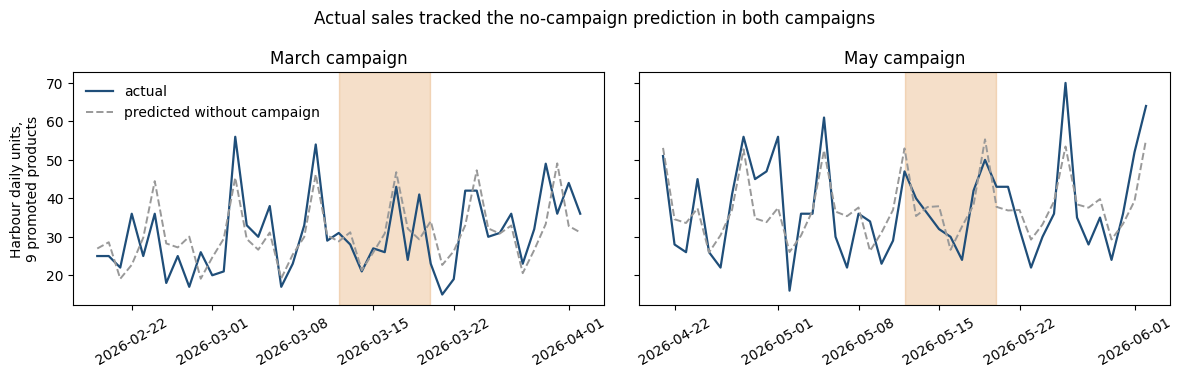

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
lin_all = LinearRegression().fit(daily.loc[CLEAN, OUTCOMES["promoted units"]["X"]], daily.loc[CLEAN, "u_H_camp"])
pred_all = pd.Series(lin_all.predict(daily[OUTCOMES["promoted units"]["X"]]), index=idx)
for ax, (ep, mask) in zip(axes, EPISODES.items()):
    start = idx[mask][0] - pd.Timedelta(days=21); end = idx[mask][-1] + pd.Timedelta(days=14)
    w = (idx >= start) & (idx <= end)
    ax.plot(idx[w], daily.loc[w, "u_H_camp"], color="#1f4e79", lw=1.6, label="actual")
    ax.plot(idx[w], pred_all[w], color="#999", lw=1.4, ls="--", label="predicted without campaign")
    ax.axvspan(idx[mask][0], idx[mask][-1] + pd.Timedelta(hours=23), color="#d9822b", alpha=0.25)
    ax.set_title(f"{ep} campaign"); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Harbour daily units,\n9 promoted products"); axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Actual sales tracked the no-campaign prediction in both campaigns")
plt.tight_layout(); plt.savefig(FIG / "campaign_counterfactual.png", dpi=150); plt.show()

## 6. From units to profit: break-even, and does it depend on costs?

Step 3 shows that recorded unit costs at Stories are fixed standard costs whose meaning is uncertain. So we also ask: **would the decision change if Harbour's true costs were different?** We scale Harbour's recorded costs by a factor *k*. Lower true costs make each extra sale more valuable and lower the break-even point.

For each campaign: gross-profit effect = actual units × discounted margin − predicted units × full-price margin. Break-even = the lift at which this reaches zero.

In [9]:
spec = OUTCOMES["promoted units"]
rows = []
for ep, mask in EPISODES.items():
    lines = P[P.Date.dt.month == idx[mask][0].month]
    q = lines.Quantity.sum()
    p_bar = (lines.Quantity * lines["Unit Price (USD)"]).sum() / q
    c_bar = (lines.Quantity * lines["Unit Cost (USD)"]).sum() / q
    pred = predict(daily, "Linear regression", spec, CLEAN, mask).sum()
    noise = cv[(cv.outcome == "promoted units") & (cv.method == "Linear regression")]["err8"]
    upper_units = q - pred + noise.quantile(0.95)
    for k in [0.5, 0.7, 1.0, 1.43]:
        m_full, m_disc = p_bar - k * c_bar, 0.85 * p_bar - k * c_bar
        need = pred * (m_full / m_disc - 1)
        rows.append({"episode": ep, "cost factor k": k, "break-even extra units": need,
                     "estimated extra units": q - pred, "plausible max extra units": upper_units,
                     "estimated GP effect $": q * m_disc - pred * m_full,
                     "break-even reached?": "yes" if upper_units >= need else "no"})
sens = pd.DataFrame(rows).set_index(["episode", "cost factor k"])
sens.round(1)

break-even extra units  estimated extra units  \
episode cost factor k                                                  
March   0.50                             54.2                   -5.4   
        0.70                             60.2                   -5.4   
        1.00                             72.0                   -5.4   
        1.43                            100.4                   -5.4   
May     0.50                             69.9                  -16.0   
        0.70                             77.7                  -16.0   
        1.00                             93.2                  -16.0   
        1.43                            130.7                  -16.0   

                       plausible max extra units  estimated GP effect $  \
episode cost factor k                                                     
March   0.50                                34.1                 -236.1   
        0.70                                34.1                 -234.0   
        1.00                                34.1                 -230.8   
        1.43                                34.1                 -226.3   
May     0.50                                23.5                 -338.7   
        0.70                                23.5                 -332.5   
        1.00                                23.5                 -323.0   
        1.43                                23.5                 -309.5   

                      break-even reached?  
episode cost factor k                      
March   0.50                           no  
        0.70                           no  
        1.00                           no  
        1.43                           no  
May     0.50                           no  
        0.70                           no  
        1.00                           no  
        1.43                           no

**Result.** k = 1.0 means recorded costs; 0.5 means true costs are half of those recorded; 1.43 means Garden-style costs. Even at k = 0.5, where every extra sale is worth the most, the break-even lift is above the plausible maximum in both campaigns. **The recommendation does not depend on the costing question from Step 3.**

## 7. Other explanations and checks

In [10]:
lin = "Linear regression"
post_rows = []
for oname in ["promoted units", "Harbour gross profit $"]:
    spec = OUTCOMES[oname]
    p = predict(daily, lin, spec, CLEAN, POST).sum()
    post_rows.append({"outcome": oname, "7 days after each campaign: effect": daily.loc[POST, spec["y"]].sum() - p})
display(pd.DataFrame(post_rows).set_index("outcome").round(1))

ids = raw.dropna(subset=["Customer ID"])
first_seen = ids.groupby("Customer ID")["Date"].min()
def share_returning(lines):
    f = lines.dropna(subset=["Customer ID"]).groupby("Customer ID")["Date"].min()
    return (first_seen[f.index] < f).mean(), len(f)
a, n1 = share_returning(P)
b, n2 = share_returning(raw[(raw.Branch == "Harbour") & raw.Date.isin(CAMP_DAYS) & ~raw.Product.isin(ITEMS)])
print(f"Identified campaign buyers seen before: {a:.1%} (n={n1}); Harbour non-promoted buyers same days: {b:.1%} (n={n2})")

dd = build_daily(raw.drop_duplicates())
c2, _, k2 = masks(dd.index)
print("\nWithout exact repeated rows (linear regression):")
for oname in ["promoted units", "Harbour gross profit $"]:
    spec = OUTCOMES[oname]
    for ep in ["March", "May"]:
        mk = c2 & (dd.index.month == (3 if ep == "March" else 5))
        print(f"  {oname}, {ep}: {dd.loc[mk, spec['y']].sum() - predict(dd, lin, spec, k2, mk).sum():+.1f}")

,7 days after each campaign: effect
outcome,
promoted units,-15.1
Harbour gross profit $,-342.8


Identified campaign buyers seen before: 92.7% (n=289); Harbour non-promoted buyers same days: 93.4% (n=713)

Without exact repeated rows (linear regression):
  promoted units, March: -5.5
  promoted units, May: -16.0
  Harbour gross profit $, March: -303.0
  Harbour gross profit $, May: -396.8


| Alternative explanation | Result |
|---|---|
| Sales moved to the week after (stock-up, delayed visits) | No rebound after either campaign |
| Customers switched from Garden/Uptown to Harbour | Would make the estimate *too favourable*. The conclusion holds |
| The campaign recruited new customers | Campaign buyers were as likely to be existing customers as other Harbour buyers that week |
| Repeated rows distort results | Removing them changes nothing material |
| Clearing desserts that would otherwise be wasted | **Not testable**: no waste or stock data. This is the main benefit that could still justify a redesigned campaign |

## 8. What is measured, what is estimated, what is assumed

| Type | Statement |
|---|---|
| **Measured** | Campaign dates, items and branch; $472 of discount on 542 units |
| **Measured** | Out-of-sample accuracy of four predictors on 130 hidden 8-day ordinary periods |
| **Estimated** | Extra promoted units: March −5 (chance range −41 to +34), May −16 (−51 to +24) |
| **Estimated** | Break-even needed +72 (March) and +93 (May) units at recorded costs; even at half the recorded costs (+54, +70) it exceeds the plausible maximum |
| **Estimated** | Harbour gross profit effect: March −$308, May −$391 |
| **Assumed (A1)** | Harbour's relationship to weekday, trend and the other branches would have continued without the campaign |
| **Assumed (A2)** | No sales moved between branches because of the campaign. If some did, the campaign looks *better* than it was |
| **Not observed** | Campaign goal, advertising cost, waste avoided, long-run customer effects |

## 9. Approaches we rejected
- **Basket comparison by discount rate:** confounded by product mix (Section 2).
- **Before/after at Harbour only:** confounded by strong growth from January to June (the same-weekday average's bias shows the problem).
- **Gradient boosting as the main estimate:** less accurate than linear regression on unseen periods.
- **Pooling March and May into one number only:** that would hide whether the two campaigns disagree. We report both.

## 10. Recommendation and the test Stories can run

**Do not repeat the 15% campaign unchanged.** If Stories wants to keep discounting these items, the next campaign should be run as a test:
- **Design:** at Harbour, over 6 weeks (about 21 offer and 21 no-offer days, enough to detect a +15% lift; see below), randomly assign days (balanced by weekday) to *offer* or *no offer*. Alternatively, randomize eligible baskets at the till, for example by receipt number.
- **Primary outcome:** gross profit per day, for the whole branch, not just units of the promoted items.
- **Log alongside it:** waste, stock-outs and advertising cost.
- **Compare against:** 10% off, and discounts only at quiet hours.

In [11]:
spec = OUTCOMES["promoted units"]
res = daily.loc[CLEAN, spec["y"]] - LinearRegression().fit(daily.loc[CLEAN, spec["X"]], daily.loc[CLEAN, spec["y"]]).predict(daily.loc[CLEAN, spec["X"]])
sd = res.std(); base = daily.loc[CLEAN & (idx.month.isin([5, 6])), spec["y"]].mean()
print(f"Daily prediction error sd: {sd:.1f} units; recent typical day: {base:.0f} promoted units")
for lift in [0.15, 0.30]:
    n = 2 * (1.96 + 0.84) ** 2 * sd ** 2 / (lift * base) ** 2
    print(f"Detect +{lift:.0%} with 80% power: ~{np.ceil(n):.0f} offer days and {np.ceil(n):.0f} no-offer days")

Daily prediction error sd: 6.5 units; recent typical day: 40 promoted units
Detect +15% with 80% power: ~20 offer days and 20 no-offer days
Detect +30% with 80% power: ~5 offer days and 5 no-offer days


## 11. Weak areas and uncertainty
- **Only two campaigns at one branch.** The data can rule out the large lift needed to break even. It cannot measure small effects precisely, and it says nothing about other branches or other products.
- **Shared customers** make the comparison branches imperfect. The bias works in the campaign's favour, so it does not threaten the conclusion, but it does blur the precise estimate.
- **Gross, not net, profit.** Advertising and staff costs would make the campaign look worse.
- **Waste avoided is the open question.** If the desserts would otherwise have been thrown away, part of the discount was not a real cost. Stories can check this in its waste logs.
- **This is an observational estimate, not proof of cause.** The randomized test in Section 10 is how Stories can establish cause.